# Coupled oscillators:

In [1]:
#Imports:
import numpy as np

#Used for checking inputs:
import string

#Used for plots:
import matplotlib.pyplot as plt

#For the extension:
import scipy as sc

In [2]:
#Function to create an empty matrix:
def matt_zeros(rows, cols):
    """This function takes an input for number of rows
    and columns and produces a matrix of zeros with the 
    specified dimensions.
    
    Args: 
        Number of rows , number of columns
    
    Returns: 
        Matrix of zeros with specified number of rows/columns
    """
    
    #Create an array of zeros with a given number of column elements per row.
    return np.array([[0.0 for i in range(cols)] for i in range(rows)])



#Function to handle data inputs:
def inputs():
    """This function makes the user input the number of oscillators
    and their respective masses and spring constants.
    
    Returns:
        Array of mass values, array of spring constants
    """
    
    
    #Number of masses inputed by user:
    n = input("How many masses does the system contain?").replace(" ", "") #Removes spaces in the input.
    
    
    #Check n is a positive integer only:
    if not n.isdigit():
        raise ValueError("n must be a positive integer!")
        
        
    #Convert to integer after checking:
    n = int(n)
    
    
    #Check n is an integer greater than or equal to 1:
    if n<1: 
        raise ValueError("The Number of masses must be a positive integer!")
     
    
    
    #Empty mass and spring constant arrays:
    masses = matt_zeros(1,n)
    springs = matt_zeros(1,n+1) #There is one extra spring than mass
    
    #Mass values:
    print("Value (Kg) of:")
    for i in range(n):
        
        #Input mass value:
        mass = input(f"Mass:{i+1}").replace(" ", "")
        
        
        #Check inputted value is valid:
        #Check there is only one decimal place: 
        if mass.count(".") > 1:
            raise ValueError("Mass cannot contain more than one decimal point!")
            
            
        #Check for incorrect punctuation: 
        if any(element in string.punctuation.replace(".", "").replace("-", "", 1) for element in mass):
            raise ValueError("Mass cannot contain punctuation!")
            
        
        #Check mass is a float:
        #Returns the error if it can't convert into a float
        try:
            value = float(mass)
        except ValueError:
            raise ValueError("Mass must be a valid finite number!")
            
            
        #Check if number is valid: 
        if float(mass) <= 0:
            raise ValueError("Mass must be greater than zero!")
            
        
        #Check the mass is finite:
        if not np.isfinite(float(mass)):
            raise ValueError("Mass must be finite!")
            
            
        #Store mass after being checked:
        masses[0][i] = mass
        
        
    #Spring values:
    print("Value (N/m) of:")
    for i in range(n+1):
        
        #Input spring value:
        spring = input(f"Spring:{i+1}").replace(" ", "")
        
        #Check inputted value is valid 
        #Check there is only one decimal place: 
        if spring.count(".") > 1:
            raise ValueError("Spring constant cannot contain more than one decimal point!")
           
        
        #Check for incorrect punctuation: 
        if any(element in string.punctuation.replace(".", "").replace("-", "", 1) for element in spring):
            raise ValueError("Spring constant cannot contain punctuation!")
            
           
        #Check spring constant is a float:
        try:
            value = float(spring)
        except ValueError:
            raise ValueError("Spring constant must be a valid finite number!")
            
            
        #Check if number is valid: 
        if float(spring) <= 0:
            raise ValueError("Spring constant must be greater than zero!")
        
        
        #Check the spring constant is finite:
        if not np.isfinite(float(spring)):
            raise ValueError("Spring constant must be finite!")
            
            
        #Store spring after being checked:
        springs[0][i] = spring
        
        
    return masses[0], springs[0] #Returns a 1D array
        

#Create matrix M: 
def matt_M(m, k):
    """This function takes an input for a mass and spring
    constant array and constructs the stiffness matrix M^(-1)K.
    
    Args:
        Mass array, spring constant array 
        
    Returns:
        Stiffness matrix: M^(-1)K
    """
    
    
    n = len(m)
    matrix_M = matt_zeros(n, n)
    
    for i in range(n):
        #Diagonal elements:

        if i == 0:
            matrix_M[i][i] = (k[i]+ k[i+1])/m[i]  #First element

        elif i == n-1:
            matrix_M[i][i] = (k[i]+ k[i+1])/m[i]  #Last element

        else:
            matrix_M[i][i] = (k[i] + k[i+1])/m[i] #Diagonal elements

        #Off diagonal elements:
        for j in range(n):

            #Values left and right of index i
            if j == i-1:
                matrix_M[i][j] = -k[j+1]/m[i] #Left of i 

            elif j == i+1:
                matrix_M[i][j] = -k[i+1]/m[i] #Right of i 
                
    return matrix_M
    

In [3]:
#Function for matrix multiplication: 
def matt_mult(A, B): #Inputs being two matrices:
    """This function takes two matrices as an input and
    multiplies them (C = A*B), while checking the inputted matries 
    are valid for matrix multiplication. 
    
    Args:
        Matrix A, matrix B
        
    Returns: 
        Matrix C
    """
    
    
    #dimensions of A/B:
    m, n = A.shape
    n2, b = B.shape
    
    #Check dimensions are valid:
    if n!= n2:
        raise ValueError("Dimensions are not valid for multiplication!")
    
    
    #Create empty matrix to append: 
    C = matt_zeros(m,b)
    
    #Calculate matrix multiplication: 
    for i in range(m):
        for j in range(b): #i/j represent rows/cols of matrix C
            for k in range(n): #K is the index used for the dot product 
                 
                #Calculate each dot product and sum into corresponding element of C:
                C[i][j] = C[i][j] + A[i][k] * B[k][j]   
    
    return C

            

# QU decomposition:

In [4]:
#Split matrix into Q/U
#Define functions needed.

#Function to find magnitude of a vector:
def col_mag_square(A):
    """This function takes an input of a column vector
    and returns its magnitude squared, while checking the
    inputted vector is indeed a column vector.
    
    Args:
        Column vector A
        
    Returns: 
        Magnitude of A squared
    """
   

    #Check dimensions of A:
    #Checks for either a 1D array or 2D arrays (both work as column vectors
    if A.ndim > 2 or (A.ndim == 2 and A.shape[1] != 1):
        raise ValueError("Given vector must be a column vector!")
    
    
    n = len(A) #length of column
    
    magnitude_square = 0 #Define variable
    
    for i in range(n):
        magnitude_square = magnitude_square + (A[i])**2 #Sum over all elements of A
        
    return magnitude_square #return the magnitude





def dot_product(A,B):
    """This function takes an input for two column
    vectors and returns their dot product while checking
    the two inputs are indeed column vectors.
    
    Args:
        Column vector A, column vector B
        
    Returns:
        Dot product of A and B
    """
    
    #Check A and B are column vectors:
    if A.ndim > 2 or (A.ndim == 2 and A.shape[1] != 1):
        raise ValueError("Given vector must be a column vector!")
        
    if B.ndim > 2 or (B.ndim == 2 and B.shape[1] != 1):
        raise ValueError("Given vector must be a column vector!")
        
    #Check A and B have the same number of elements:
    if len(A) != len(B):
        raise ValueError("A and B must have the same number of elements!")
        
        
    #Number of elements:
    n = len(A)
    
    #Variable to overwrite:
    val = 0
    
    #Loop over elements:
    for i in range(n):
        #Add the nth elements product to val:
        val = val + A[i]*B[i]
    
    return val


def matrix_q_u(A):
    """This function takes an inputted matrix
    and performs QU decompositon, returning 
    matrix Q and U.
    
    Args:
        Matrix A
    
    Returns:
        Matrix Q, matrix U
    """
    
    
    #Define matrices f, Q and U with dimensions of A:
    n, m = A.shape
    matrix_f = matt_zeros(n, m)
    matrix_q = matt_zeros(n, m)
    matrix_u = matt_zeros(n, m)
    
    #Construct matrix f:
    for i in range(n):
        #This keeps matrix_f (c_k) fixed for each
        #loop over j so all f_k's up to k-1 can subtracted 
        matrix_f[:,i] = A[:,i] #Define c_k
        
        
        for j in range(i): #Loops up to (i-1) as per the theory: 
            
            #This loop subtracts each q_k term from c_k:
            vector_norm = matrix_f[:,j]/col_mag_square(matrix_f[:,j])
            product = dot_product(matrix_f[:,i],matrix_f[:,j])
            
            #Construct column of f:
            matrix_f[:,i] = matrix_f[:,i] - product*vector_norm #Construct matrix f
            #Storing matrix_f allows it to be reused to calculate matrix_u 
            
            
    #Construct matrix_q:
    for k in range(n):
        mod_f = np.sqrt(col_mag_square(matrix_f[:,k])) #magnitude of f_k
        matrix_q[:,k] = matrix_f[:,k]/mod_f #q_k
        
    
   #Construct matrix u:
    for i in range(n):
        for j in range(i,n): #Upper right triangle of matrix U
            #Diagonal condition:
            if i == j:
                mod_f = np.sqrt(col_mag_square(matrix_f[:,i]))
                matrix_u[i,i] = mod_f
           
            #Non diagonal cases:
            else:
                dot_prod = dot_product(A[:,j], matrix_q[:,i])
                matrix_u[i,j] = dot_prod

    #Return matrix_q and matrix_u to be used for decomposition: 
    return matrix_q, matrix_u



In [5]:
#Function for eigenvalue tolerance:
def tollerance(A_0,A_1, toll):
    """This function takes an input for an old and 
    new A matrix where it compares the diagonal elements 
    and checks for convergence within a given tollerance.
    
    Args:
        Matrix A (old), matrix A (new)
        
    Returns:
        False (convergence not met), True (convergence met)
    """
    
    
    #Dimensons:
    n, m = A_0.shape
    
    #Loops over all eigenvalues:
    for i in range(n):
        #Diagonal values for both matrices:
        original = A_0[i][i]
        new = A_1[i][i]
        
        
        #Use units of the frequency:
        original_hz = np.sqrt(original)/(2*np.pi)
        new_hz = np.sqrt(new)/(2*np.pi)
        
        
        #Calculate difference:
        change = abs(original_hz - new_hz) #We dont care about sign hence use abs
        
        
        #Returns false while still converging or nan
        if change >= toll or np.isnan(change):
            return False
     
    
    #When all eigenvalues have converged this will return TRUE
    return True
        
    

#Function for QU decomposition:
def q_u_decomp(A, toll= None):
    """This function takes a matrix A, performs QU decomposition
    and uses the grand schmidt method to converge A's diagonal 
    elements to its eigen values within a given tolerance while
    returning the number of itterations and values to be used in
    with matplotlib. Maximum itteration number is 10,000.
    
    Args:
        Matrix A, Tolerance (deffault val = 1e-4)
        
    Returns:
        Number of itterations till convergence, vibrational eigen values
    """
    
    
    n, m = A.shape
    
    A_0 = A
    
    #Keep track of iteration numbers: 
    f = 0
    #Max number of iterations. This is important as some cases may not converge:
    max_iterations = 10000
    
    #Deffault toll value if none is given:
    if toll is None:
        toll = 1e-4 #Value has been chosen based on testing
    
    #Record all itteration counts to plot:
    itterations = []
    
    #Record all intemediary diagonal values:
    eig_steps = []
    
    while f < max_iterations:
        #Save the original matrix to check for convergence:
        A_0 = A.copy()
        
        #QU decomposition: 
        q, u = matrix_q_u(A)
        A = matt_mult(u,q)
        
        #Increase iteration count:
        f = f+1
        
        #Save current diagonal values of matrix A:
        eig_steps.append([A[i, i] for i in range(n)])
        
        
        #Check for convergence: 
        if tollerance(A_0, A, toll) == True:
            
            #Saves f value for the plot:
            itterations.append(f)
            break
    
    if f == max_iterations:
        raise RuntimeError("The eigenvalues did not converge!")
      
    
    #Save the eigenvalues:
    eigvals = []
    for i in range(n):
        eigvals.append(A[i,i]) #Diagonal elements contain the eigen values.
        
    
    return np.sqrt(eigvals)/(2*np.pi), itterations, np.sqrt(eig_steps)/(2*np.pi)

def coupled_oscillator_frequencies(m = None, k = None, toll = None):
    """This function makes the user input number of masses,
    mass values and spring constant values with a given tollerance. Constructing a stiffness 
    matrix for the system and performing QU decomposition until its 
    eigen values converges. It then outputs the number of itterations
    with the systems eigen values.
    
    Args:
        Number of masses, values of each mass, 
        values of each spring constant, tollerance
        
    Returns:
        Number of itterations till convergence, vibrational eigen values
    """
    
    
    #Gather system information if not given:
    if m is None and k is None:
        m,k = inputs()
    
    #Create Stiffness matrix:
    A = matt_M(m,k)
    
    #Find eigenvals/itterations:
    frequencies, itterations, steps = q_u_decomp(A, toll)
    return frequencies, itterations, steps

# Testing convergence:

What tollerance is suitable for the system:

In [6]:
#Tollerances for testing:
tolls = np.array([1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6])

#Test system: Mass, springs
m = np.array([1, 2, 2, 1, 3])             
k = np.array([50, 8, 50, 8, 50, 20])     

#Construct stiffness matrix:
A = matt_M(m, k)

#Loop over all tollerances:
for toll in tolls:
    print(f"{q_u_decomp(A, toll)[0]}, Tollerance = {toll}")

[1.22593331 1.18383295 1.35079534 0.4476585  0.26285471], Tollerance = 0.1
[1.24468998 1.36349401 1.15133408 0.44466418 0.25854641], Tollerance = 0.01
[1.37778609 1.23953637 1.13982206 0.44466474 0.25854545], Tollerance = 0.001
[1.37913836 1.23819021 1.13964979 0.44466474 0.25854545], Tollerance = 0.0001
[1.37924812 1.23814528 1.13956577 0.44466474 0.25854545], Tollerance = 1e-05
[1.37923418 1.23820217 1.13952083 0.44466474 0.25854545], Tollerance = 1e-06


### Plotting convergence: 

Plot of the eigen valuew converging with a given tollerance: 

[1.37923418 1.23820217 1.13952083 0.44466474 0.25854545]


-5

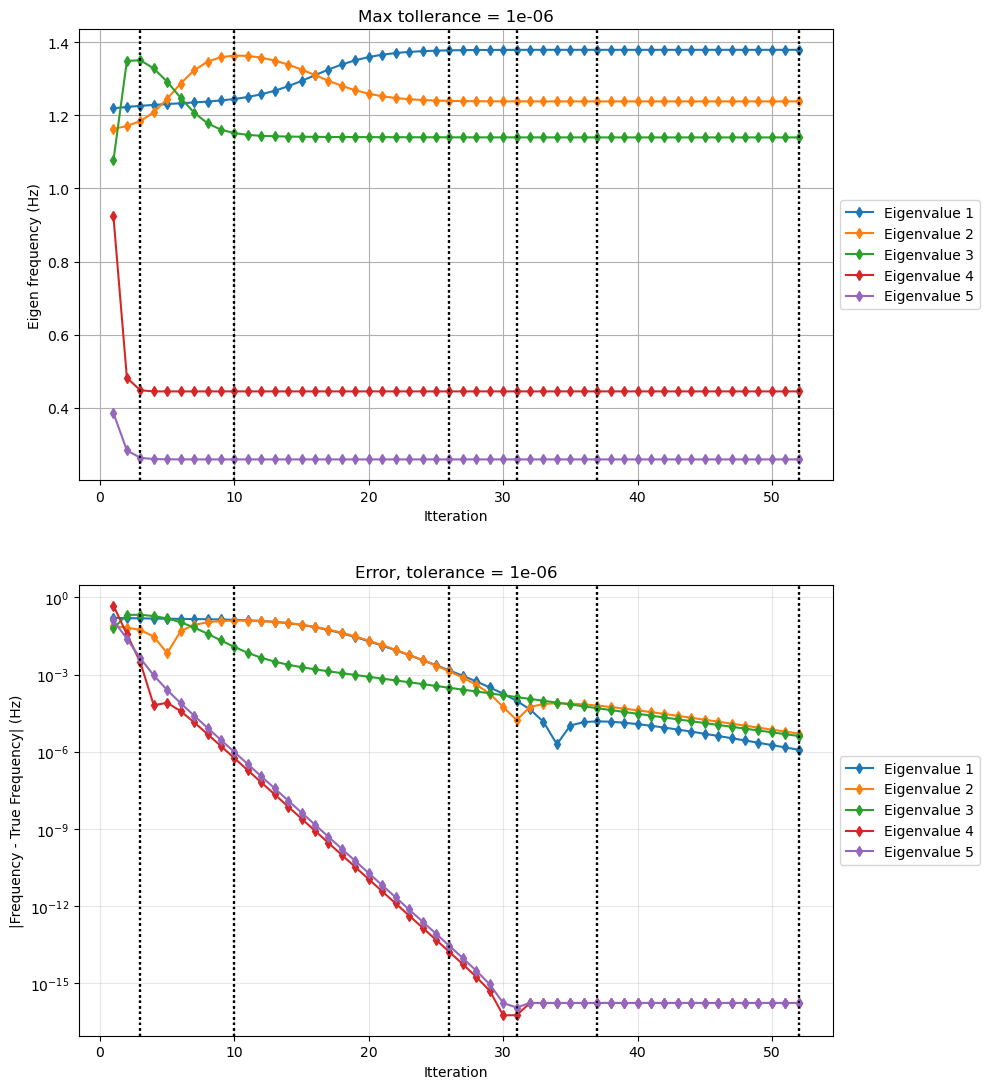

In [7]:
#high tollerance "True value" from numpy:
ref_freqs = np.sqrt(np.linalg.eigvals(A)) / (2 * np.pi)
ref_freqs = np.sort(ref_freqs)[::-1]

#Index of the smallest tolerance value:
i = np.argmin(tolls)

#Empty lists to store data in:
all_eigvals = []
all_itterations = []
all_eigsteps = []


#Loop over all candidate tollerance values:
for toll in tolls:
    #Compute data:
    eigvals, itterations, eig_steps = q_u_decomp(A, toll)
    
    #Save values:
    all_eigvals.append(eigvals)
    all_itterations.append(itterations)
    all_eigsteps.append(eig_steps)

    
#Convert into one array of itteration counts for each tollerance: 
all_itterations = np.array(all_itterations).flatten()


#Smallest tollerance case:
total_itterations = len(all_eigsteps[i])

#Number of eigenvalues:
n_eigs = len(all_eigsteps[i][0])


#Define plot:
fig, (ax,ax_err) = plt.subplots(2, 1, figsize=(10, 11))



#Loop over each eigen value:
for j in range(n_eigs):
        
    #Data to store/plot:
    history = []
    error = []
        
    #Loop over each itteration:
    for k in range(total_itterations):
        
        value = all_eigsteps[i][k][j]
        
        #Save data to plot:
        history.append(value)  
        error.append(abs(value - ref_freqs[j]))

    #Plot the values converging:
    ax.plot(range(1, total_itterations + 1), history, 
            marker = 'd', markersize = 5, linestyle = '-', label=f"Eigenvalue {j+1}")
        
    #Plot the error:
    ax_err.semilogy(range(1, total_itterations + 1), error,
            marker = 'd', markersize = 5, linestyle = '-', label=f"Eigenvalue {j+1}")
    
    #Loop over all tollerances:
    for t in range(len(tolls)):
        
        #Plot on both axes
        for axes in (ax, ax_err):
            #Plot a verticle line for each convergence itteration:
            axes.axvline(all_itterations[t], linestyle=':', color='black')


#Axis parameters:
ax.set_title(f"Max tollerance = {tolls[i]}")
ax.set_xlabel("Itteration")
ax.set_ylabel("Eigen frequency (Hz)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.grid()
    
ax_err.set_title(f"Error, tolerance = {tolls[i]}")
ax_err.set_xlabel("Itteration")
ax_err.set_ylabel("|Frequency - True Frequency| (Hz)")
ax_err.grid(alpha=0.3)
ax_err.legend(loc="center left", bbox_to_anchor=(1, 0.5))

fig.tight_layout(h_pad=3)

print(all_eigvals[5])

#fig.savefig("convergences.png", dpi=300, bbox_inches="tight")
abs(all_eigsteps[i][30][0] - ref_freqs[0])
all_itterations[2] - all_itterations[3]

# Testing my functions:

Here I am using numpy to check my functions are correct against numpys matrix functions.

In [8]:
#Test matrices: 5X5 (too cumborsome to do by hand)
matt_1 = np.array([[1,2,31,84,5],
                   [1,22,3,4,5],
                   [9,22,23,40,15],
                   [1,2,1,4,5],
                   [1,2,3,4,5]]) 

matt_2 = np.array([[1,7,5,4,10],
                   [2,3,3,40,5],
                   [2,72,3,4,5],
                   [15,24,3,43,5],
                   [7,22,3,4,5]]) 


#Test my matrix multiplication is correct:
#Numpys returns integers hence use allclose()
np.allclose(matt_mult(matt_1, matt_2), np.matmul(matt_1, matt_2))

True

In [9]:
#Test matt_zeros:
np.allclose(matt_zeros(5,5), np.zeros((5,5)))

True

In [10]:
#Check column vector:
#Test array:
test_col = np.array([1,9,7,4,6,10])

#My array returns magnitude squared hence sqrt it:
mag_test = np.sqrt(col_mag_square(test_col))

#Numpy:
mag = np.linalg.norm(test_col)

#Check both are equal:
print(mag_test == mag)

#Testing the col_mag_square() functions input checks for a 2D array:
test_col2 = np.array([[1],[9],[7],[4],[6],[10]])
mag_test2 = col_mag_square(test_col2)

True


In [11]:
#Testing dot_product() function:

#Test matrices:
arr_1 = np.array([1,8,6,3])
arr_2 = np.array([6,43,8,2])

#Perform dot product:
dot_test = dot_product(arr_1, arr_2)

#Numpy dot product:
dot_true = np.dot(arr_1, arr_2)

dot_test == dot_true

True

In [12]:
#Testing q_u_decomp() function against:
#test system:

test_mass = np.array([1, 6, 5, 3, 7, 2])
test_springs = np.array([13, 22, 41, 25, 12, 15, 45])

#Construct stiffness matrix:
test_matrix = matt_M(test_mass, test_springs)

#Fin eigenvalues:
function_freqs = q_u_decomp(test_matrix)[0]

#Find eigenvalues and convert to Hz:
#Sort them in descending order:
np_freqs = np.sort(np.sqrt(np.linalg.eigvals(test_matrix))/(2*np.pi))[::-1]

print(function_freqs)
print(np_freqs)

#True for the given accuracy rtol:
np.allclose(function_freqs, np_freqs, rtol=1e-4)

[0.98354022 0.88056793 0.7354099  0.52402226 0.27967807 0.14320856]
[0.98354024 0.88055574 0.73542444 0.52402229 0.27967807 0.14320856]


True

In [13]:
#High precision case:
toll = 1e-15

#Include tollerance:
freq_toll = q_u_decomp(test_matrix, toll)[0]

#Maximum difference:
print(np.max(np.abs(freq_toll - np_freqs)))

#Show agreement to high precision:
print(np.allclose(freq_toll, np_freqs, rtol=1e-12, atol=1e-12))

2.6645352591003757e-15
True


# Comparison with analytically solvable systems:

I have analytically solved systems:

N=1

N=2

N=3

Both cases have been solve for m_1=m_2=m_3 = m, k_1=k_2=k_3=k_4=k and m=k=1

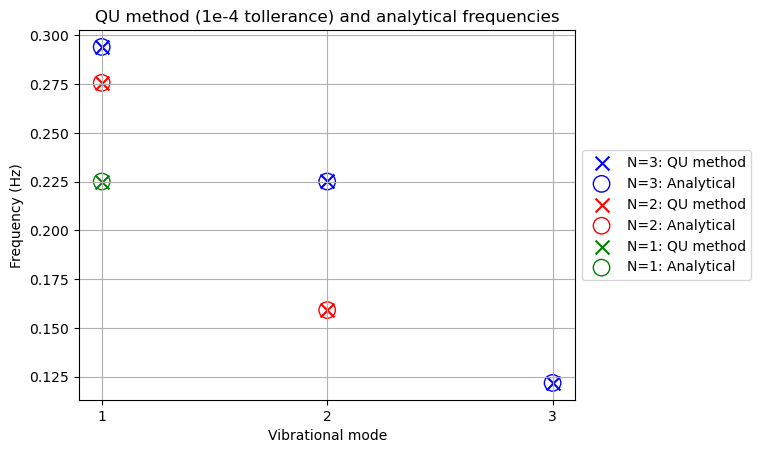

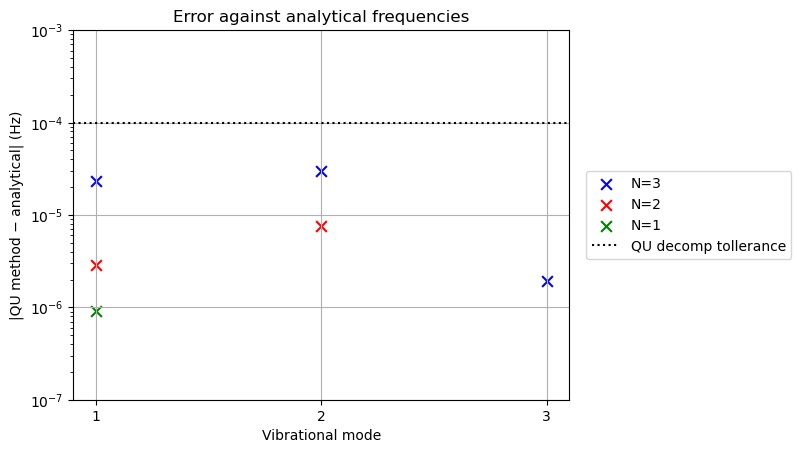

In [14]:
#Analytically obtained values in Hz (3dp):
n1_eigfreqs = np.array([0.22508])
n2_eigfreqs = np.array([0.27566, 0.15915])
n3_eigfreqs = np.array([0.29408, 0.22508, 0.12181])

#Calculate eigvals using Q_U decomposition: 
#Define mass and spring arrays:
n1_m = np.array([1]) #N=1
n2_m = np.array([1,1]) #N=2
n3_m = np.array([1,1,1]) #N=3

n1_k = np.array([1,1])
n2_k = np.array([1,1,1])
n3_k = np.array([1,1,1,1])


#Define stiffness matrix for both cases:
n1_A = matt_M(n1_m, n1_k)
n2_A = matt_M(n2_m, n2_k)
n3_A = matt_M(n3_m, n3_k)


#Complete docomposition with default tollerance:
n1_freqs, n1_iters, n1_steps = q_u_decomp(n1_A)
n2_freqs, n2_iters, n2_steps = q_u_decomp(n2_A)
n3_freqs, n3_iters, n3_steps = q_u_decomp(n3_A)


#Number of eigen values:
n1_modes = 1
n2_modes = np.arange(1, len(n2_freqs) + 1)
n3_modes = np.arange(1, len(n3_freqs) + 1)


#Define axis to plot on:
fig_n, ax_n = plt.subplots()
fig_nerr, ax_nerr = plt.subplots()


#Plot the eigen values:
#Plot N=3 case:
ax_n.scatter(n3_modes, n3_freqs, marker = 'x', label = "N=3: QU method", 
             s = 100, color = 'blue') #Calculated

ax_n.scatter(n3_modes, n3_eigfreqs, marker = 'o', facecolors = 'none',
             label = "N=3: Analytical", s = 140, color = 'blue') #Analytical
 

#Plot N=2 case:
ax_n.scatter(n2_modes, n2_freqs, marker = 'x', label = "N=2: QU method", 
             s = 100, color = 'red') #Calculated

ax_n.scatter(n2_modes, n2_eigfreqs, marker = 'o', facecolors = 'none',
             label = "N=2: Analytical", s = 140, color = 'red') #Analytical
  
#Plot N=1 case:
ax_n.scatter(n1_modes, n1_freqs, marker = 'x', label = "N=1: QU method", 
             s = 100, color = 'green') #Calculated

ax_n.scatter(n1_modes, n1_eigfreqs, marker = 'o', facecolors = 'none',
             label = "N=1: Analytical", s = 140, color = 'green') #Analytical




ax_n.set_title("QU method (1e-4 tollerance) and analytical frequencies")
ax_n.set_xlabel("Vibrational mode")
ax_n.set_ylabel("Frequency (Hz)")
ax_n.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_n.set_xticks([1, 2, 3])
ax_n.grid()
#fig_n.savefig("analytical.png", dpi=300, bbox_inches="tight")
#Plot the errors:
#Calculate diff between actual values and 
n1_diff = abs(n1_freqs - n1_eigfreqs)
n3_diff = abs(n3_freqs - n3_eigfreqs)
n2_diff = abs(n2_freqs - n2_eigfreqs)


#Plot data points:
ax_nerr.scatter(n3_modes, n3_diff, marker='x', color='blue', s=60, label="N=3")
ax_nerr.scatter(n2_modes, n2_diff, marker='x', color='red', s=60, label="N=2")
ax_nerr.scatter(n1_modes, n1_diff, marker='x', color='green', s=60, label="N=1")

#Plot the tollerance: (tollerance here is default, hence 1e-4)
ax_nerr.axhline(1e-4, linestyle=':', color='black', label = 'QU decomp tollerance')


#Set plot parameters:
ax_nerr.set_yscale('log')
ax_nerr.set_title("Error against analytical frequencies")
ax_nerr.set_xlabel("Vibrational mode")
ax_nerr.set_ylabel("|QU method − analytical| (Hz)")
ax_nerr.set_xticks([1, 2, 3])
ax_nerr.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax_nerr.set_ylim(1e-7, 1e-3)
ax_nerr.grid()
#fig_nerr.savefig("analytical_error.png", dpi=300, bbox_inches="tight")

## Plotting a general N system:

How many masses does the system contain? 5


Value (Kg) of:


Mass:1 1
Mass:2 1
Mass:3 1
Mass:4 1
Mass:5 1


Value (N/m) of:


Spring:1 1
Spring:2 1
Spring:3 1
Spring:4 1
Spring:5 1
Spring:6 1


[0.30733494 0.27580625 0.22508127 0.15915494 0.08238466]


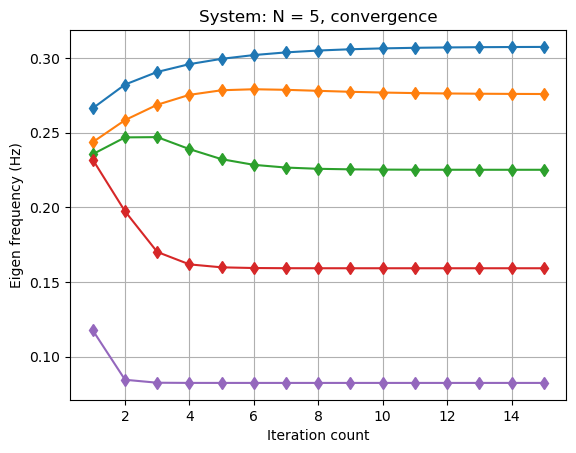

In [15]:
# Calculate data from inputs:
N_freq, N_itterations, N_steps = coupled_oscillator_frequencies()

#Define axis:
N_fig, N_ax = plt.subplots()
    
#Loop over all eigenvalues:
for i in range(len(N_freq)):
       
    #Plot data converging:
    N_ax.plot(range(1, len(N_steps) + 1), N_steps[:,i], #selects column i
              marker = 'd', linestyle = '-', label = f'Vibrational mode: {i+1}')
    
#Set axis parameters:
N_ax.set_title(f"System: N = {len(N_freq)}, convergence")
N_ax.set_xlabel("Iteration count")
N_ax.set_ylabel("Eigen frequency (Hz)")
#N_ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
N_ax.grid()

#N_fig.savefig("N50.png", dpi=300, bbox_inches="tight")
print(N_freq)

## Varying spring constant:

0.07083061316114518

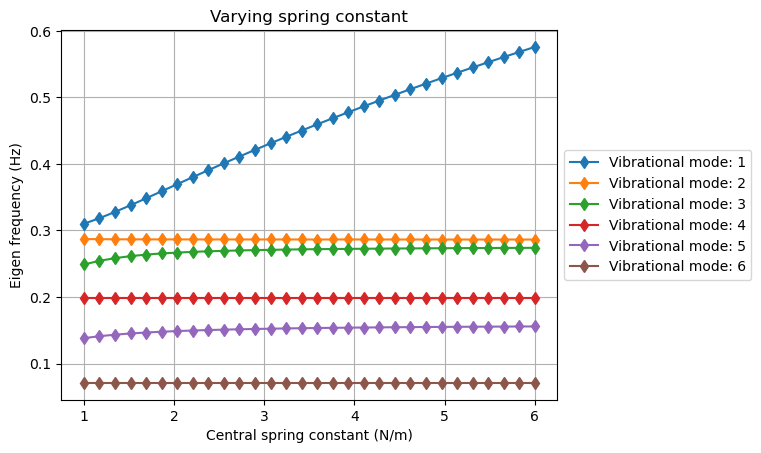

In [16]:
#Define the initial system: Use an N=6 system
mass_k = np.array([1,1,1,1,1,1])
springs_k = np.array([1.,1.,1.,1.,1.,1.,1.]) #Use decimal points to stop numpy rounding spring values

#Empty list to store spring values
k4_list = []

#Empty list for eigenvalues:
eigvals_k = []

#Loop creates a list of increasing values:
k4_list = np.linspace(1,6,30)
   

#Loop over all springs:

for j in range(len(k4_list)):
    #Change the middle spring:
    springs_k[3] = k4_list[j]
    
    
    #Define stiffness matrix for the given spring:
    A_k = matt_M(mass_k, springs_k)
    
    #Complete docomposition with default tollerance:
    k_freqs, k_iters, k_steps = q_u_decomp(A_k)
    
    #Store eigenvalues for spring j:
    eigvals_k.append(k_freqs)

    
#Define figure axis:
fig_k, ax_k = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_k[0])):
    #Values to store:
    vals = []
    
    #Loop over springs:
    for z in range(len(eigvals_k)):
        vals.append(eigvals_k[z][k])
        
    #Plot data:
    ax_k.plot(k4_list, vals, marker = 'd', linestyle = '-', label = f'Vibrational mode: {k+1}')
  

ax_k.set_title("Varying spring constant")
ax_k.set_xlabel("Central spring constant (N/m)")
ax_k.set_ylabel("Eigen frequency (Hz)")
ax_k.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_k.grid()
eigvals_k[29][5]
#fig_k.savefig("central_spring.png", dpi=300, bbox_inches="tight")

## Weak middle spring constant:

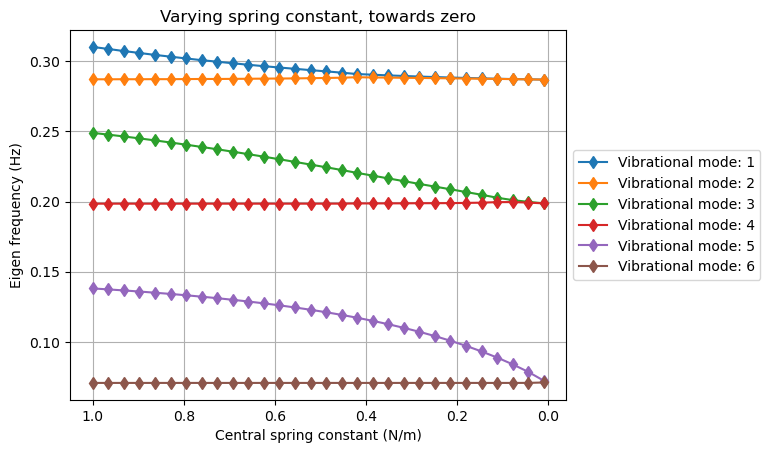

In [17]:
#Define the initial system: Use an N=6 system
mass_kw = np.array([1,1,1,1,1,1])
springs_kw = np.array([1.,1.,1.,1.,1.,1.,1.]) #Use decimal points to stop numpy rounding spring values

#Empty list to store mass values
kw4_list = []

#Empty list for eigenvalues:
eigvals_kw = []

#Loop creates a list of increasing values:
kw4_list = np.linspace(1e-2,1,30)
   

#Loop over all masses:

for j in range(len(kw4_list)):
    #Change the middle mass:
    springs_kw[3] = kw4_list[j]
    
    
    #Define stiffness matrix for the given mass:
    A_kw = matt_M(mass_kw, springs_kw)
    
    #Complete docomposition with default tollerance:
    kw_freqs, kw_iters, kw_steps = q_u_decomp(A_kw)
    
    #Store eigenvalues for mass j:
    eigvals_kw.append(kw_freqs)

    
#Define figure axis:
fig_kw, ax_kw = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_kw[0])):
    #Values to store:
    vals = []
    
    #Loop over masses:
    for z in range(len(eigvals_kw)):
        vals.append(eigvals_kw[z][k])
        
    #Plot data:
    ax_kw.plot(kw4_list, vals, marker = 'd', linestyle = '-', label = f'Vibrational mode: {k+1}')
  

ax_kw.set_title("Varying spring constant, towards zero")
ax_kw.set_xlabel("Central spring constant (N/m)")
ax_kw.set_ylabel("Eigen frequency (Hz)")
ax_kw.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_kw.grid()
ax_kw.invert_xaxis()
#fig_kw.savefig("weak_mid_spring.png", dpi=300, bbox_inches="tight")

## Varying an end spring:

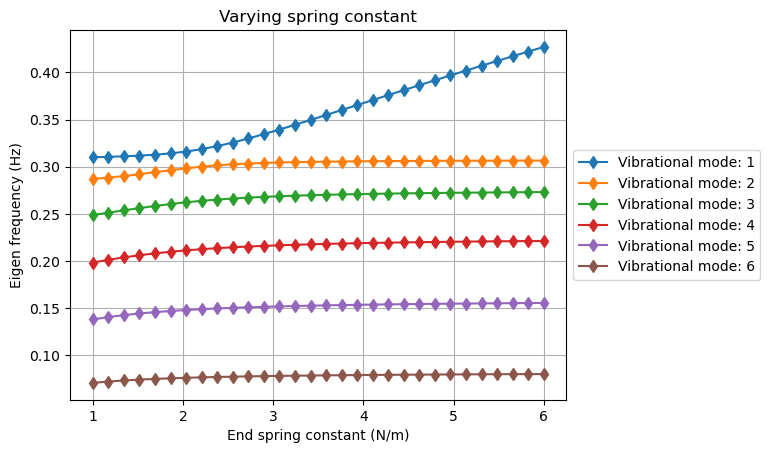

In [18]:
#Define the initial system: Use an N=6 system
mass_k_end = np.array([1,1,1,1,1,1])
springs_k_end = np.array([1.,1.,1.,1.,1.,1.,1.]) #Use decimal points to stop numpy rounding spring values

#Empty list to store spring values
k7_list = []

#Empty list for eigenvalues:
eigvals_k_end = []

#Loop creates a list of increasing values:
k7_list = np.linspace(1,6,30)
   

#Loop over all springs:

for j in range(len(k7_list)):
    #Change the middle spring:
    springs_k_end[6] = k7_list[j]
    
    
    #Define stiffness matrix for the given spring:
    A_k_end = matt_M(mass_k_end, springs_k_end)
    
    #Complete docomposition with default tollerance:
    k_freqs_end, k_iters_end, k_steps_end = q_u_decomp(A_k_end)
    
    #Store eigenvalues for spring j:
    eigvals_k_end.append(k_freqs_end)

    
#Define figure axis:
fig_k_end, ax_k_end = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_k_end[0])):
    #Values to store:
    vals = []
    
    #Loop over springs:
    for z in range(len(eigvals_k_end)):
        vals.append(eigvals_k_end[z][k])
        
    #Plot data:
    ax_k_end.plot(k7_list, vals, marker = 'd', linestyle = '-', label = f'Vibrational mode: {k+1}')
  

ax_k_end.set_title("Varying spring constant")
ax_k_end.set_xlabel("End spring constant (N/m)")
ax_k_end.set_ylabel("Eigen frequency (Hz)")
ax_k_end.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_k_end.grid()
#fig_k_end.savefig("end_spring.png", dpi=300, bbox_inches="tight")

## Varying mass:

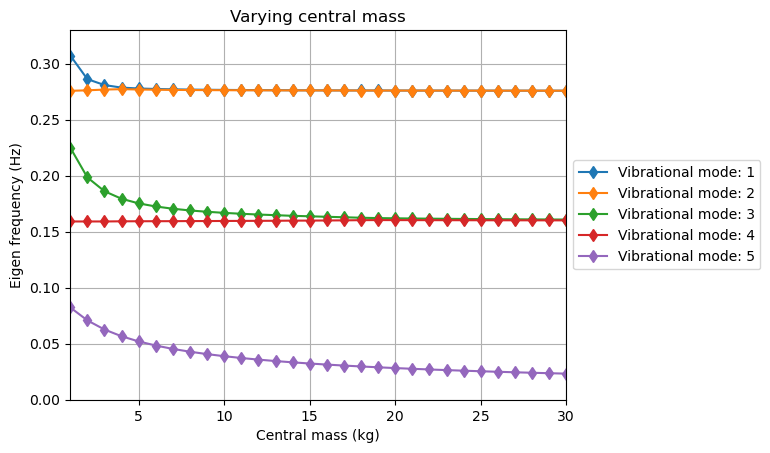

In [19]:
#Define the initial system: Use an N=5 system
mass_m = np.array([1.,1.,1.,1.,1.]) #Use decimal points to stop numpy rounding mass values
springs_m = np.array([1,1,1,1,1,1])

#Empty list to store mass values
m3_list = []

#Empty list for eigenvalues:
eigvals_m = []

#Loop creates evenly spaces values from 1-5:
m3_list = np.linspace(1,30,30)
   

#Loop over all masses:

for j in range(len(m3_list)):
    #Change the middle mass:
    mass_m[2] = m3_list[j]
    
    
    #Define stiffness matrix for the given mass:
    A_m = matt_M(mass_m, springs_m)
    
    #Complete docomposition with default tollerance:
    m_freqs, m_iters, m_steps = q_u_decomp(A_m)
    
    #Store eigenvalues for mass j:
    eigvals_m.append(m_freqs)

    
#Define figure axis:
fig_m, ax_m = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_m[0])):
    #Values to store:
    vals = []
    
    #Loop over masses:
    for z in range(len(eigvals_m)):
        vals.append(eigvals_m[z][k])
        
    #Plot data:
    ax_m.plot(m3_list, vals, marker = 'd', linestyle = '-', 
              label = f'Vibrational mode: {k+1}')
  

ax_m.set_title("Varying central mass")
ax_m.set_xlabel("Central mass (kg)")
ax_m.set_ylabel("Eigen frequency (Hz)")
ax_m.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_m.set_xlim(1,max(m3_list))
ax_m.set_ylim(0,0.33)
ax_m.grid()
#fig_m.savefig("central_mass.png", dpi=300, bbox_inches="tight")

## Varying a weak central mass:

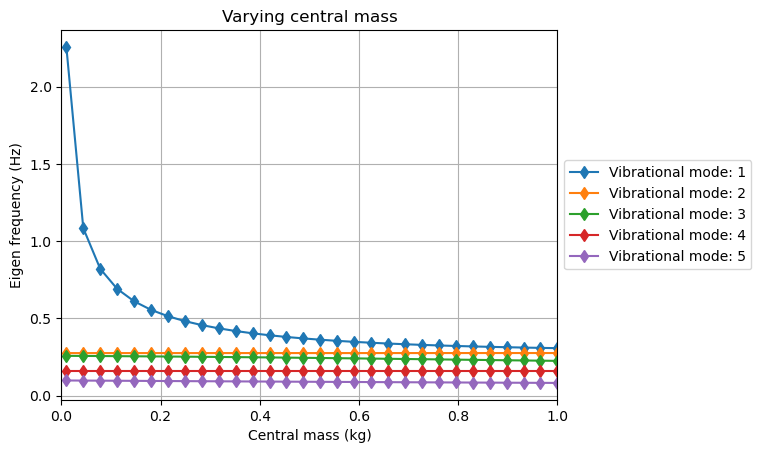

In [20]:
#Define the initial system: Use an N=5 system
mass_mw = np.array([1.,1.,1.,1.,1.]) #Use decimal points to stop numpy rounding mass values
springs_mw = np.array([1,1,1,1,1,1])

#Empty list to store mass values
mw3_list = []

#Empty list for eigenvalues:
eigvals_mw = []

#Loop creates evenly spaces values from 1-5:
mw3_list = np.linspace(1e-2,1,30)
   

#Loop over all masses:

for j in range(len(mw3_list)):
    #Change the middle mass:
    mass_mw[2] = mw3_list[j]
    
    
    #Define stiffness matrix for the given mass:
    A_mw = matt_M(mass_mw, springs_mw)
    
    #Complete docomposition with default tollerance:
    mw_freqs, mw_iters, mw_steps = q_u_decomp(A_mw)
    
    #Store eigenvalues for mass j:
    eigvals_mw.append(mw_freqs)

    
#Define figure axis:
fig_mw, ax_mw = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_mw[0])):
    #Values to store:
    vals = []
    
    #Loop over masses:
    for z in range(len(eigvals_mw)):
        vals.append(eigvals_mw[z][k])
        
    #Plot data:
    ax_mw.plot(mw3_list, vals, marker = 'd', linestyle = '-', 
              label = f'Vibrational mode: {k+1}')
  

ax_mw.set_title("Varying central mass")
ax_mw.set_xlabel("Central mass (kg)")
ax_mw.set_ylabel("Eigen frequency (Hz)")
ax_mw.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_mw.set_xlim(0,max(mw3_list))
ax_mw.grid()
#fig_mw.savefig("weak_central_mass.png", dpi=300, bbox_inches="tight")

## Varying an end mass:

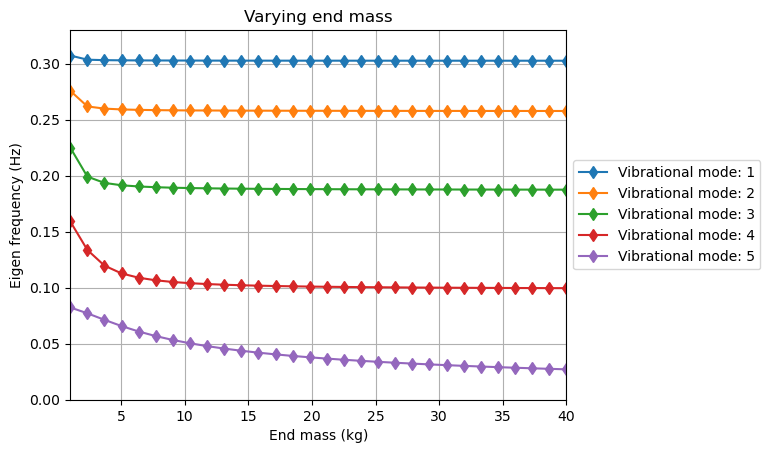

In [21]:
#Define the initial system: Use an N=5 system
mass_m_end = np.array([1.,1.,1.,1.,1.]) #Use decimal points to stop numpy rounding mass values
springs_m_end = np.array([1,1,1,1,1,1])

#Empty list to store mass values
m5_list = []

#Empty list for eigenvalues:
eigvals_m_end = []

#Loop creates evenly spaces values from 1-5:
m5_list = np.linspace(1,40,30)
   

#Loop over all masses:

for j in range(len(m5_list)):
    #Change the middle mass:
    mass_m_end[4] = m5_list[j]
    
    
    #Define stiffness matrix for the given mass:
    A_m_end = matt_M(mass_m_end, springs_m_end)
    
    #Complete docomposition with default tollerance:
    m_freqs_end, m_iters_end, m_steps_end = q_u_decomp(A_m_end)
    
    #Store eigenvalues for mass j:
    eigvals_m_end.append(m_freqs_end)

    
#Define figure axis:
fig_m_end, ax_m_end = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_m_end[0])):
    #Values to store:
    vals = []
    
    #Loop over masses:
    for z in range(len(eigvals_m_end)):
        vals.append(eigvals_m_end[z][k])
        
    #Plot data:
    ax_m_end.plot(m5_list, vals, marker = 'd', linestyle = '-', 
              label = f'Vibrational mode: {k+1}')
  

ax_m_end.set_title("Varying end mass")
ax_m_end.set_xlabel("End mass (kg)")
ax_m_end.set_ylabel("Eigen frequency (Hz)")
ax_m_end.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_m_end.set_xlim(1,max(m5_list))
ax_m_end.set_ylim(0,0.33)
ax_m_end.grid()
#fig_m_end.savefig("end_mass.png", dpi=300, bbox_inches="tight")

# Extension task:

Derrivation is included in the report, essentially I have taken the first order taylor expansion of the 
coulomb force around the equilibrium (assuming size of oscillations are small) giving the new terms found
in the function bellow.

I use this to test a few cases involving the charge and seperations of the particles:

In [22]:
#Function to compute the derrived stiffness matrix:
def Coulomb_stiffness(m, k, q, x):
    """This function takes an input for a mass, spring
    constant, charge and position array and constructs 
    the stiffness matrix M^(-1)K.
    
    Args:
        Mass array, spring constant array, 
        Mass positions (in ascending order), charge array
        
    Returns:
        Stiffness matrix: M^(-1)K
    """
    
    #Create an empty matrix to append:
    n = len(m)
    matrix_M = matt_zeros(n, n)
    
    #To append the coulomb coefficient into:
    coulomb_coeffs = matt_zeros(n,n)
    
    
    for i in range(n):
        #Diagonal elements:

        if i == 0:
            matrix_M[i][i] = (k[i]+ k[i+1])/m[i]  #First element

        elif i == n-1:
            matrix_M[i][i] = (k[i]+ k[i+1])/m[i]  #Last element

        else:
            matrix_M[i][i] = (k[i] + k[i+1])/m[i] #Diagonal elements

        #Off diagonal elements:
        for j in range(n):
        
            #Values left and right of index i
            if j == i-1:
                matrix_M[i][j] = -k[j+1]/m[i] #Left of i 

            elif j == i+1:
                matrix_M[i][j] = -k[i+1]/m[i] #Right of i 
                
                
            #Add in the coulomb terms:    
            #Preventing masses 'interacting' with themselves:
            if i!=j:
                
                #Calculate Coulomb coefficient:
                #Factor 2 from Taylor expansion:
                charges = 2*q[i]*q[j]
                distance_diff = abs(x[i] - x[j]) 
                coulomb_coeffs[i][j] = charges/(4*np.pi*sc.constants.epsilon_0*(distance_diff**3))
                   
                #Offdiagonal:
                matrix_M[i][j] = matrix_M[i][j] - coulomb_coeffs[i][j]/m[i]
                
                #Digaonal:
                matrix_M[i][i] = matrix_M[i][i] + coulomb_coeffs[i][j]/m[i]
            
    return matrix_M


#Inputs including q and x:
def inputs_coulomb():
    """This function makes the user input the number of oscillators
    and their respective masses and spring constants.
    
    Returns:
        Array of mass values, array of spring constants
    """
    
    
    #Number of masses inputed by user:
    n = input("How many masses does the system contain?").replace(" ", "") #Removes spaces in the input.
    
    
    #Check n is a positive integer only:
    if not n.isdigit():
        raise ValueError("n must be a positive integer!")
        
        
    #Convert to integer after checking:
    n = int(n)
    
    
    #Check n is an integer greatrer than or equal to 1:
    if n<1: 
        raise ValueError("The Number of masses must be a positive integer!")
     
    
    
    #Empty arrays to append:
    masses = matt_zeros(1,n)
    springs = matt_zeros(1,n+1) #There is one extra spring than mass
    charges = matt_zeros(1,n)
    positions = matt_zeros(1,n)
    
    #Mass values:
    print("Value (Kg) of:")
    for i in range(n):
        
        #Input mass value:
        mass = input(f"Mass:{i+1}").replace(" ", "")
        
        
        #Check inputted value is valid:
        #Check there is only one decimal place: 
        if mass.count(".") > 1:
            raise ValueError("Mass cannot contain more than one decimal point!")
            
            
        #Check for incorrect punctuation: 
        if any(element in string.punctuation.replace(".", "").replace("-", "", 1) for element in mass):
            raise ValueError("Mass cannot contain punctuation!")
         
        #Check mass is a float:
        try:
            value = float(mass)
        except ValueError:
            raise ValueError("Mass must be a valid finite number!")
            
        #Check if number is valid: 
        if float(mass) <= 0:
            raise ValueError("Mass must be greater than zero!")
        
        
        #Check the mass is finite:
        if not np.isfinite(float(mass)):
            raise ValueError("Mass must be finite!")
            
            
        #Store mass after being checked:
        masses[0][i] = mass
        
        
    #Spring values:
    print("Value (N/m) of:")
    for i in range(n+1):
        
        #Input spring value:
        spring = input(f"Spring:{i+1}").replace(" ", "")
        
        #Check inputted value is valid 
        #Check there is only one decimal place: 
        if spring.count(".") > 1:
            raise ValueError("Spring constant cannot contain more than one decimal point!")
           
        
        #Check for incorrect punctuation: 
        if any(element in string.punctuation.replace(".", "").replace("-", "", 1) for element in spring):
            raise ValueError("Spring constant cannot contain punctuation!")
          
        
        #Check spring constant is a valid float:
        try:
            value = float(spring)
        except ValueError:
            raise ValueError("Spring constant must be a valid finite number!")
        
        
        #Check if number is valid: 
        if float(spring) <= 0:
            raise ValueError("Spring constant must be greater than zero!")
        
        
        #Check the spring constant is finite:
        if not np.isfinite(float(spring)):
            raise ValueError("Spring constant must be finite!")
            
            
        #Store spring after being checked:
        springs[0][i] = spring

    print("Value (C) of:")
    for i in range(n):
            
        #Input mass value:
        charge = input(f"Charge:{i+1}").replace(" ", "")
            
            
        #Check inputted value is valid:
        #Check there is only one decimal place: 
        if charge.count(".") > 1:
            raise ValueError("Charge cannot contain more than one decimal point!")
                
                
        #Check for incorrect punctuation: 
        if any(element in string.punctuation.replace(".", "").replace("-", "", 1) for element in charge):
            raise ValueError("Charge cannot contain punctuation!")
         
        #Check charge is a float:
        try:
            value = float(charge)
        except ValueError:
            raise ValueError("Charge must be a valid finite number!")
           
        
        #Check the charge is finite:
        if not np.isfinite(float(charge)):
            raise ValueError("Charge must be finite!")
            
        #Store charge after being checked:
        charges[0][i] = charge
        


    #Position values:
    print("Value (m) of:")
    for i in range(n):
        
        #Input mass value:
        position = input(f"Position:{i+1}").replace(" ", "")
        
        
        #Check inputted value is valid:
        #Check there is only one decimal place: 
        if position.count(".") > 1:
            raise ValueError("Position cannot contain more than one decimal point!")
            
            
        #Check for incorrect punctuation: 
        if any(element in string.punctuation.replace(".", "").replace("-", "", 1) for element in position):
            raise ValueError("Position cannot contain punctuation!")
         
        
        #Check position is a valid float:
        try:
            value = float(position)
        except ValueError:
            raise ValueError("Position must be a valid finite number!")
        
        
        #Check position is a valid number: 
        if float(position) <= 0:
            raise ValueError("Position must be greater than zero!")
            
        #Check the position is finite:
        if not np.isfinite(float(position)):
            raise ValueError("position must be finite!")
        
        
        #Check they're in ascending order and seperated:
        if i>0 and float(position) <= positions[0][i-1]:
            raise ValueError("Positions must be in ascending order and there must be a seperation between masses!")
        
        
        #Store mass after being checked:
        positions[0][i] = position
        
    return masses[0], springs[0], charges[0], positions[0] #Returns a 1D array



def coulomb_oscillator_frequencies(toll = None):
    """This function makes the user input number of masses,
    mass values and spring constant values with a given tollerance. Constructing a stiffness 
    matrix for the system and performing QU decomposition until its 
    eigen values converges. It then outputs the number of itterations
    with the systems eigen values.
    
    Args:
        Number of masses, values of each mass, 
        values of each spring constant, tollerancev(default: 1e-4)
        
    Returns:
        Number of itterations till convergence, vibrational eigen values
    """
    
    
    #Gather system information:
    m,k,q,x = inputs_coulomb()
    
    #Create Stiffness matrix:
    A = Coulomb_stiffness(m,k,q,x)
    
    #Find eigenvals/itterations:
    frequencies, itterations, steps = q_u_decomp(A, toll)
    return frequencies, itterations, steps

##  Recovering previous results under the limit q->0:

In [23]:
#test case:
m_c = np.array([1,2,1])
k_c = np.array([1,2,2,1])
q_c = np.array([0,0,0])
x_c = np.array([1,2,3])

#Calculate the stiffness matrix:
M_c = Coulomb_stiffness(m_c, k_c, q_c, x_c)

#Find eigen frequencies:
freqs_c, itters_c, steps_c = q_u_decomp(M_c)

#Find eigenvalues with the mass and spring only stiffness matrix:
M_normal = matt_M(m_c, k_c)

#Find frequencies:
freqs_norm, itters_norm, steps_norm = q_u_decomp(M_normal)

#See if original result is recovered.
freqs_norm == freqs_c

array([ True,  True,  True])

## Varying middle charge:

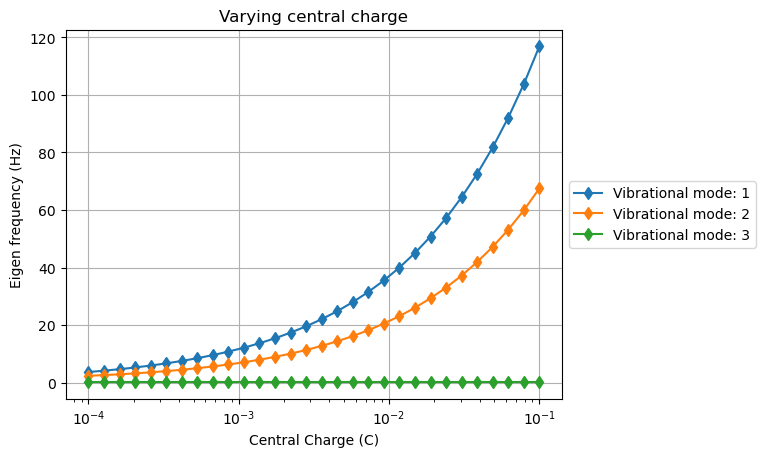

In [24]:
#Define the initial system: Use an N=3 system
m_midc = np.array([1,1,1]) #Use decimal points to stop numpy rounding mass values
k_midc = np.array([1,1,1,1])
q_midc = np.array([1e-4,1.,1e-4]) #Varry the middle charge
x_midc = np.array([1,2,3])


#Empty list to store mass values
q2_list = []


#Empty list for eigenvalues:
eigvals_midc = []


#Array of charge values:
# 10** paired with semilogx plot makes it clearer to see:
q2_list = 10 ** np.linspace(-4,-1,30)
   

#Loop over all masses:
for j in range(len(q2_list)):
    #Change the middle charge:
    q_midc[1] = q2_list[j]
    
    
    #Define stiffness matrix with the coulomb force included:
    A_midc = Coulomb_stiffness(m_midc, k_midc, q_midc, x_midc)
    
    #Complete docomposition with default tollerance:
    freqs_midc, iters_midc, steps_midc = q_u_decomp(A_midc)
    
    #Store eigenvalues for charge j:
    eigvals_midc.append(freqs_midc)

    
#Define figure axis:
fig_midc, ax_midc = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_midc[0])):
    #Values to store:
    vals = []
    
    #Loop over masses:
    for z in range(len(eigvals_midc)):
        vals.append(eigvals_midc[z][k])
        
    #Plot data: semilogx allows us to see the data clearer
    ax_midc.semilogx(q2_list, vals, marker = 'd', linestyle = '-', 
              label = f'Vibrational mode: {k+1}')
  

ax_midc.set_title("Varying central charge")
ax_midc.set_xlabel("Central Charge (C)")
ax_midc.set_ylabel("Eigen frequency (Hz)")
ax_midc.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_midc.grid()
#fig_midc.savefig("mid_charge.png", dpi=300, bbox_inches="tight")

## Varying the position of the end charge:

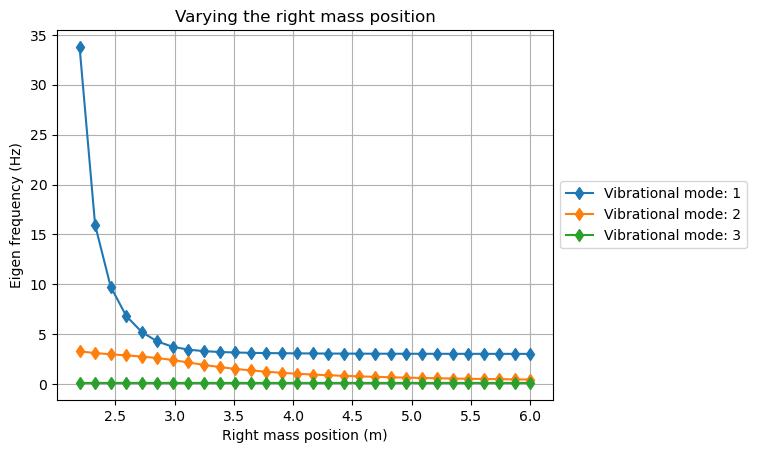

In [25]:
#Define the initial system: Use an N=3 system
m_endx = np.array([1,1,1]) #Use decimal points to stop numpy rounding mass values
k_endx = np.array([1,1,1,1])
q_endx = np.array([1e-4,1e-4,1e-4]) 
x_endx = np.array([1.,2.,1.]) #Varry the end distance

#Empty list to store mass values
x3_list = []

#Empty list for eigenvalues:
eigvals_endx = []


#Array of charge values:
x3_list = np.linspace(2.2,6,30)
   

#Loop over all masses:

for j in range(len(x3_list)):
    #Change the middle charge:
    x_endx[2] = x3_list[j]
    
    
    #Define stiffness matrix with the coulomb force included:
    A_endx = Coulomb_stiffness(m_endx, k_endx, q_endx, x_endx)
    
    #Complete docomposition with default tollerance:
    freqs_endx, iters_endx, steps_endx = q_u_decomp(A_endx)
    
    #Store eigenvalues for charge j:
    eigvals_endx.append(freqs_endx)

    
#Define figure axis:
fig_endx, ax_endx = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_endx[0])):
    #Values to store:
    vals = []
    
    #Loop over masses:
    for z in range(len(eigvals_endx)):
        vals.append(eigvals_endx[z][k])
        
    #Plot data: semilogx allows us to see the data clearer
    ax_endx.plot(x3_list, vals, marker = 'd', linestyle = '-', 
              label = f'Vibrational mode: {k+1}')
  

ax_endx.set_title("Varying the right mass position")
ax_endx.set_xlabel("Right mass position (m)")
ax_endx.set_ylabel("Eigen frequency (Hz)")
ax_endx.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_endx.grid()
#fig_endx.savefig("end_position.png", dpi=300, bbox_inches="tight")

## Negative charge:

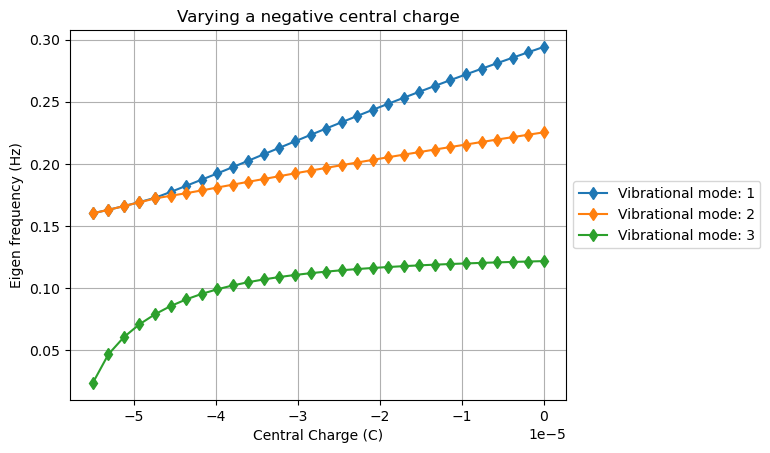

In [26]:
#Define the initial system: Use an N=3 system
m_neg = np.array([1,1,1]) 
k_neg = np.array([1,1,1,1])
q_neg = np.array([1e-6,1.,1e-6]) #Varry the middle charge
x_neg = np.array([1,2,3])

#Empty list to store mass values
q2_list = []

#Empty list for eigenvalues:
eigvals_neg = []


#Array of charge values:
#
#
#-5.5e-5 is approximately the largest negative value it can handle!
q2_list = np.linspace(-5.5e-5, 0, 30)
   

#Loop over all masses:

for j in range(len(q2_list)):
    #Change the middle charge:
    q_neg[1] = q2_list[j]
    
    
    #Define stiffness matrix with the coulomb force included:
    A_neg = Coulomb_stiffness(m_neg, k_neg, q_neg, x_neg)
    
    #Complete docomposition with default tollerance:
    freqs_neg, iters_neg, steps_neg = q_u_decomp(A_neg)
    
    #Store eigenvalues for charge j:
    eigvals_neg.append(freqs_neg)

    
#Define figure axis:
fig_neg, ax_neg = plt.subplots()



#Loop over all eigenvalues:
for k in range(len(eigvals_neg[0])):
    #Values to store:
    vals = []
    
    #Loop over masses:
    for z in range(len(eigvals_neg)):
        vals.append(eigvals_neg[z][k])
        
    #Plot data:
    ax_neg.plot(q2_list, vals, marker = 'd', linestyle = '-', 
              label = f'Vibrational mode: {k+1}')
  

ax_neg.set_title("Varying a negative central charge")
ax_neg.set_xlabel("Central Charge (C)")
ax_neg.set_ylabel("Eigen frequency (Hz)")
ax_neg.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax_neg.grid()
#fig_neg.savefig("neg_charge.png", dpi=300, bbox_inches="tight")

## General N case:

How many masses does the system contain? 5


Value (Kg) of:


Mass:1 1
Mass:2 2
Mass:3 3
Mass:4 4
Mass:5 5


Value (N/m) of:


Spring:1 1
Spring:2 2
Spring:3 3
Spring:4 4
Spring:5 5
Spring:6 6


Value (C) of:


Charge:1 1e-4
Charge:2 1e-4
Charge:3 1e-4
Charge:4 1e-4
Charge:5 1e-4


Value (m) of:


Position:1 1
Position:2 2
Position:3 3
Position:4 4
Position:5 5


[2.95105789 2.1952072  1.69572316 1.06239357 0.10817727]


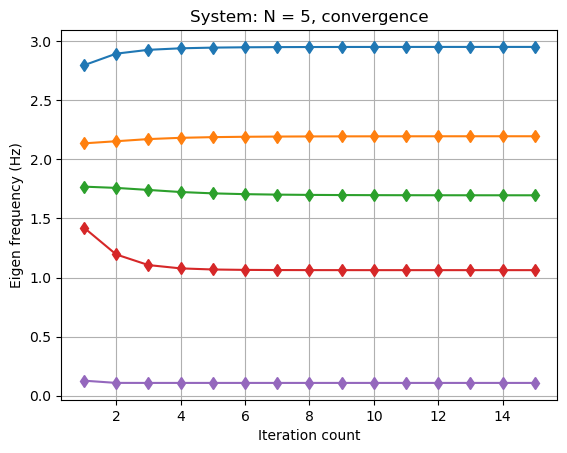

In [27]:
# Calculate data from inputs:
Nc_freq, Nc_itterations, Nc_steps = coulomb_oscillator_frequencies()

#Define axis:
Nc_fig, Nc_ax = plt.subplots()
    
#Loop over all eigenvalues:
for i in range(len(Nc_freq)):
       
    #Plot data converging:
    Nc_ax.plot(range(1, len(Nc_steps) + 1), Nc_steps[:,i], #selects column i
              marker = 'd', linestyle = '-', label = f'Vibrational mode: {i+1}')
    
#Set axis parameters:
Nc_ax.set_title(f"System: N = {len(Nc_freq)}, convergence")
Nc_ax.set_xlabel("Iteration count")
Nc_ax.set_ylabel("Eigen frequency (Hz)")
#N_ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
Nc_ax.grid()
#Nc_fig.savefig("N20_coulomb.png", dpi=300, bbox_inches="tight")
print(Nc_freq)